# SampleNTT: predict rejection from one power trace

**Husky + CW308_STM32F4 · variable-time sampler A0**

This lab demonstrates a narrow, testable leakage claim: a classifier can predict whether the **first 12-bit candidate is accepted** from one power capture of an unseen public seed. Train on known seeds, freeze the classifier, then test on different seeds.

The capture window was fixed using the previously validated experiment. Both classes have the same total sampling workload. This demonstrates local accept/reject leakage; it does not recover an ML-KEM key.

Start a fresh kernel using chipwhisperer-new/.venv. Run the seven code cells in order. Hardware routines, raw records and metadata stay in the companion directory.

## 1. Setup

Use 128 seeds per class for training and another 128 per class for testing: **512 captures, one per seed**. Gain starts at the previously usable 10 dB. To resume an interrupted run, set RESUME_RUN to its printed results folder; completed captures and the frozen model are reused.

In [1]:
from pathlib import Path
import sys, importlib
REPO = Path.home() / 'Desktop/work/chipwhisperer-new'
LAB = REPO / 'jupyter/courses/custom/mlkem-samplentt-power-lab'
sys.path.insert(0, str(LAB))
import capture.lab as lab_workflow
importlib.reload(lab_workflow)

PER_CLASS = 128
GAIN_DB = 10.0
RESUME_RUN = None
lab = lab_workflow.SampleNTTPowerLab(REPO, per_class=PER_CLASS,
                                    gain_db=GAIN_DB, resume=RESUME_RUN)

Results: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/results/runs/proof-20261028T232020Z-ca5338


## 2. Prepare and verify the hardware

This builds and programs the **STM32F4 target**, connects Husky, verifies the sampler identity and polynomial digest, and warms the target before collecting data. It also restores normal USB–FPGA bus timing.

The fixed 512-sample window covers about 17.4 µs near the first candidate pair, at four ADC samples per CPU cycle. It is tied to the calibrated firmware image; a different image stops the lab and requires recalibration. Clipping and capture errors remain enabled.

In [2]:
check = lab.prepare()

Detected known STMF32: STM32F40xxx/41xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 15203 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 15203 bytes
Verified measurement firmware: fbe72dbef701cfd52eb08b3ca895c66112c9296e3d89797c0ff2301b318f91f3
Digest checks passed; ADC range: 1704 to 2441


## 3. Capture training data

Seeds are balanced between first-candidate acceptance and rejection. Every seed takes exactly 160 pairs, with a valid second candidate and output completion on the final candidate. Trial order is randomized; every successful capture is checkpointed and verified. Failures stop capture rather than silently dropping seeds. Rerun this cell to resume after fixing an error.

In [4]:
lab.scope.adc.lo_gain_errors_disabled = True
lab.scope.adc.clip_errors_disabled = False
lab.scope.adc.errors = 0
lab.recorder.snapshot = str(lab.scope)

lab.collect_training()

Training captures:   0%|          | 0/249 [00:00<?, ?it/s]

256 verified training captures; one per seed.


256

In [3]:
lab.collect_training();

Training captures:   0%|          | 0/256 [00:00<?, ?it/s]

RuntimeError: ADC reported errors: gain too low error, 

## 4. Freeze the distinguisher

The classifier selects 16 power-sample positions and fits a regularized linear model using **training data only**. The window was fixed before this run. The model, threshold and capture settings are saved before test capture. A separate total-duration classifier provides a timing baseline.

In [5]:
lab.freeze();

Classifier frozen: 96feace7c32c8675fa7d4652ef73bb7c2ba0219fcddc15a329d5aabac5aeee5f
Window fixed before collection; sample points fitted using training data only.


## 5. Capture fresh test seeds

These seeds have not appeared in training or earlier saved experiments. The capture code requires the frozen model and unchanged settings. Do not return to model or window selection after inspecting this test.

In [6]:
lab.collect_test();

Fresh test captures:   0%|          | 0/256 [00:00<?, ?it/s]

256 verified fresh-test captures; model unchanged.


## 6. Evaluate the claim

**Balanced accuracy** averages accept and reject recall; chance is 50%. **AUC** measures how well the scores separate the classes. Confidence bounds account for finite test seeds even if every prediction is correct. The permutation p-value tests label association with the already frozen predictions.

A convincing run has a power accuracy interval above 50% and a small p-value. Compare against total timing and inspect the waveform/score plots. A negative result is retained. Results apply to this balanced seed population, warmed target and exact build; fresh-session replication strengthens the claim.

| Model | Correct | Balanced accuracy (95% CI) | AUC |
|---|---:|---:|---:|
| Power | 255/256 | 99.6% (95.9–100.0%) | 0.999 |
| Total timing | 135/256 | 52.7% (42.5–62.8%) | 0.521 |

Chance balanced accuracy: 50%. Fixed-model label-permutation p: 2.24e-74
Evidence supports first-candidate discrimination in this setup.
Inspect report.json for failed/retried captures before interpreting the result.


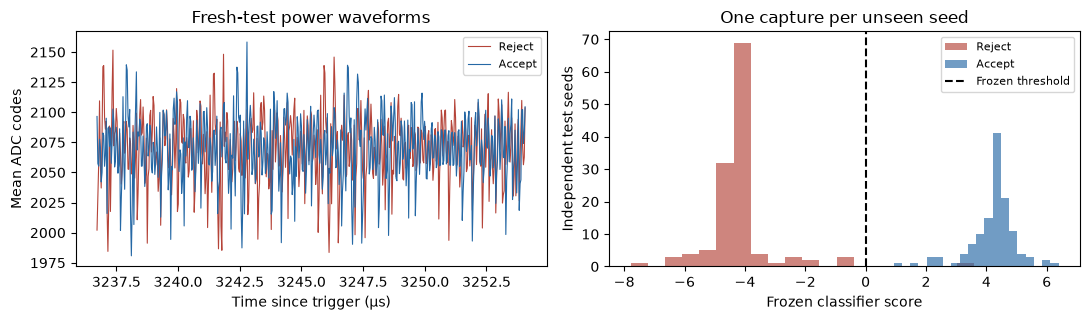

Saved: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/results/runs/proof-20261028T232020Z-ca5338/report.json


In [7]:
report = lab.results()

## 7. Disconnect

Release the board for another notebook.

In [ ]:
lab.close()

The [full calibration and experimental method](Full%20SampleNTT%20Method.ipynb), original measured run, and Git checkpoint remain available. Source integrity checks, per-trace digests, raw waveforms, failure logs and model fingerprints are retained by the helper code.